# **Wine quality Classification**

In [1]:
import pandas as pd

## Loading data and understanding data

In [5]:
data = pd.read_csv("winequality-red.csv",sep=";")

In [6]:
data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [9]:
data.shape

(1599, 12)

In [16]:
data.dtypes

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

In [18]:
data.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000
mean,8.310596,0.529478,0.272333,2.523400,0.088124,15.893304,46.825975,0.996709,3.309787,0.658705,10.432315,5.623252
std,1.736990,0.183031,0.195537,1.352314,0.049377,10.447270,33.408946,0.001869,0.155036,0.170667,1.082065,0.823578
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996700,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.430000,2.600000,0.091000,21.000000,63.000000,0.997820,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


## Checking null values

In [10]:
data.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

## Detect duplicate values and remove duplicates

In [14]:
data.duplicated().sum()

np.int64(240)

In [15]:
data = data.drop_duplicates()

print("Shape after removing duplicates:", data.shape)
print("Remaining duplicates:", data.duplicated().sum())

Shape after removing duplicates: (1359, 12)
Remaining duplicates: 0


In [19]:
print(data['quality'].value_counts().sort_index())

quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


## Target catergorization

In [21]:
def categorize_quality(quality):
    if quality <= 5:
        return 'Low'
    elif quality == 6:
        return 'Medium'
    else:
        return 'High'

data['quality_category'] = data['quality'].apply(categorize_quality)

print(data[['quality', 'quality_category']].head(10))

    quality quality_category
0         5              Low
1         5              Low
2         5              Low
3         6           Medium
5         5              Low
6         5              Low
7         7             High
8         7             High
9         5              Low
10        5              Low


C:\Users\star\AppData\Local\Temp\ipykernel_11204\3687649251.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['quality_category'] = data['quality'].apply(categorize_quality)


In [29]:
data = pd.read_csv("winequality-red.csv", sep=";")

data = data.drop_duplicates()

print(data.shape)
print(data.columns.tolist())

(1359, 12)
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


In [30]:
data['quality_category'] = data['quality'].apply(categorize_quality)

print(data['quality_category'].value_counts())

quality_category
Low       640
Medium    535
High      184
Name: count, dtype: int64


## Feature Engineering

In [35]:
data['total_acidity'] = (
    data['fixed acidity'] +
    data['volatile acidity'] +
    data['citric acid']
)

data['sulfur_dioxide_ratio'] = (
    data['free sulfur dioxide'] /
    data['total sulfur dioxide']
)

data['alcohol_to_density'] = (
    data['alcohol'] / data['density']
)

print(data.head())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
5            7.4              0.66         0.00             1.8      0.075   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
5                 13.0                  40.0   0.9978  3.51       0.56   

   alcohol  quality quality_category  total_acidity  sulfur_dioxide_ratio  \
0      9.

## Feature selection

In [39]:
X = data.drop(columns=['quality', 'quality_category'])
y = data['quality_category']

In [40]:
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k=5)

X_selected = selector.fit_transform(X, y)

In [41]:
selected_features = X.columns[selector.get_support()]

print(selected_features)

Index(['volatile acidity', 'total sulfur dioxide', 'sulphates', 'alcohol',
       'alcohol_to_density'],
      dtype='object')


In [42]:
feature_scores = pd.DataFrame({
    'Feature': X.columns,
    'Score': selector.scores_
})

print(feature_scores.sort_values(
    by='Score', ascending=False
))

                 Feature       Score
10               alcohol  248.080033
13    alcohol_to_density  246.447579
1       volatile acidity  102.700819
9              sulphates   44.931040
6   total sulfur dioxide   41.697382
12  sulfur_dioxide_ratio   40.786357
2            citric acid   36.625541
7                density   27.535244
4              chlorides   11.451953
0          fixed acidity   11.169190
11         total_acidity    8.492892
5    free sulfur dioxide    5.019527
8                     pH    2.484292
3         residual sugar    2.282922


In [43]:
X_selected_df = pd.DataFrame(
    X_selected,
    columns=selected_features
)

print(X_selected_df.head())

   volatile acidity  total sulfur dioxide  sulphates  alcohol  \
0              0.70                  34.0       0.56      9.4   
1              0.88                  67.0       0.68      9.8   
2              0.76                  54.0       0.65      9.8   
3              0.28                  60.0       0.58      9.8   
4              0.66                  40.0       0.56      9.4   

   alcohol_to_density  
0            9.420726  
1            9.831461  
2            9.829488  
3            9.819639  
4            9.420726  


## Train-test-Split

In [44]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,y, 
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

In [50]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1087, 14)
X_test: (272, 14)
y_train: (1087,)
y_test: (272,)


## Feature scaling
Standard Scaler

In [46]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [51]:
print("Before Scaling:")
print(X_train.head())

print("\nAfter Scaling:")
print(X_train_scaled[:5])

Before Scaling:
      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
1027            6.4             0.795         0.00             2.2      0.065   
371             7.9             0.240         0.40             1.6      0.056   
537             8.1             0.825         0.24             2.1      0.084   
493             8.7             0.690         0.31             3.0      0.086   
443            10.0             0.440         0.49             2.7      0.077   

      free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
1027                 28.0                  52.0  0.99378  3.49       0.52   
371                  11.0                  25.0  0.99670  3.32       0.87   
537                   5.0                  13.0  0.99720  3.37       0.77   
493                  23.0                  81.0  1.00020  3.48       0.74   
443                  11.0                  19.0  0.99630  3.23       0.63   

      alcohol  total_acidity  sulf

## Principal Component analysis (PCA)

In [47]:
from sklearn.decomposition import PCA

pca = PCA()

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

In [48]:
print(pca.explained_variance_ratio_)

[2.89986224e-01 1.86274849e-01 1.23024315e-01 9.63568014e-02
 8.35141443e-02 7.23530148e-02 5.18361301e-02 4.28446152e-02
 2.87960645e-02 1.50879361e-02 5.56644352e-03 4.35930339e-03
 1.58551667e-07 2.40463976e-17]


In [49]:
print(pca.explained_variance_ratio_.cumsum())

[0.28998622 0.47626107 0.59928539 0.69564219 0.77915633 0.85150935
 0.90334548 0.94619009 0.97498616 0.99007409 0.99564054 0.99999984
 1.         1.        ]


In [52]:
pca_95 = PCA(n_components=0.95)

X_train_pca_95 = pca_95.fit_transform(X_train_scaled)
X_test_pca_95 = pca_95.transform(X_test_scaled)

print("Training shape:", X_train_pca_95.shape)
print("Testing shape:", X_test_pca_95.shape)

print("Components selected:", pca_95.n_components_)
print("Variance retained:", pca_95.explained_variance_ratio_.sum())

Training shape: (1087, 9)
Testing shape: (272, 9)
Components selected: 9
Variance retained: 0.9749861584800088


## Model Building with original features

### Random Forest classifier

In [53]:
from sklearn.ensemble import RandomForestClassifier

In [54]:
rf_original = RandomForestClassifier(
    n_estimators = 100,
    random_state = 42
)
rf_original.fit(X_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [55]:
y_pred_original = rf_original.predict(X_test)

## Model Evaluation

In [56]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred_original))

print("Precision:", precision_score(
    y_test, y_pred_original, average='macro'
))

print("Recall:", recall_score(
    y_test, y_pred_original, average='macro'
))

print("F1 Score:", f1_score(
    y_test, y_pred_original, average='macro'
))

Accuracy: 0.5955882352941176
Precision: 0.6035353535353535
Recall: 0.541697582512419
F1 Score: 0.5612120334154233


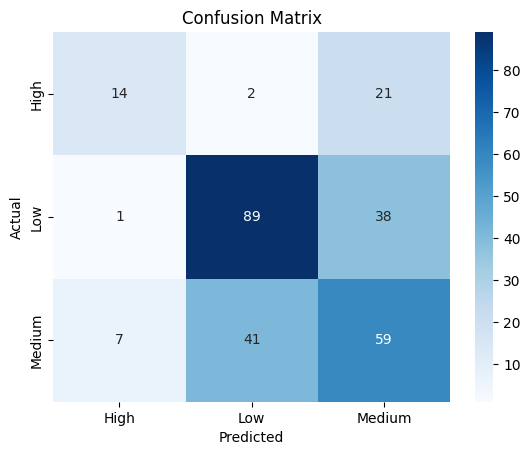

In [57]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_original)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['High', 'Low', 'Medium'],
    yticklabels=['High', 'Low', 'Medium']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [59]:
print(classification_report(
    y_test,
    y_pred_original
))

              precision    recall  f1-score   support

        High       0.64      0.38      0.47        37
         Low       0.67      0.70      0.68       128
      Medium       0.50      0.55      0.52       107

    accuracy                           0.60       272
   macro avg       0.60      0.54      0.56       272
weighted avg       0.60      0.60      0.59       272



## Model building with Feature selection

Random forest with feature selection

In [61]:
print("Training shape:", X_train_selected.shape)
print("Testing shape:", X_test_selected.shape)
print("Selected features:", selected_features_final.tolist())

Training shape: (1087, 5)
Testing shape: (272, 5)
Selected features: ['volatile acidity', 'citric acid', 'sulphates', 'alcohol', 'alcohol_to_density']


In [62]:
from sklearn.ensemble import RandomForestClassifier

rf_selected = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_selected.fit(X_train_selected, y_train)

y_pred_selected = rf_selected.predict(X_test_selected)

## Model Evaluation

In [ ]:

print("Accuracy:", accuracy_score(y_test, y_pred_selected))

print("Precision:", precision_score(
    y_test, y_pred_selected, average='macro'
))

print("Recall:", recall_score(
    y_test, y_pred_selected, average='macro'
))

print("F1 Score:", f1_score(
    y_test, y_pred_selected, average='macro'
))

Accuracy: 0.5625
Precision: 0.5265016488038071
Recall: 0.4895741243580029
F1 Score: 0.49979296210944524


## Model Building with PCA

Random forest with PCA

In [64]:
rf_pca = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_pca.fit(X_train_pca_95, y_train)

y_pred_pca = rf_pca.predict(X_test_pca_95)

## Model Evaluation

In [65]:
print("Accuracy:", accuracy_score(y_test, y_pred_pca))

print("Precision:", precision_score(
    y_test, y_pred_pca, average='macro'
))

print("Recall:", recall_score(
    y_test, y_pred_pca, average='macro'
))

print("F1 Score:", f1_score(
    y_test, y_pred_pca, average='macro'
))

Accuracy: 0.6213235294117647
Precision: 0.6312509499924001
Recall: 0.5747808263871348
F1 Score: 0.5941671309621991


## Final Report

In [67]:
import pandas as pd
from IPython.display import display
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

comparison = pd.DataFrame({
    'Original Features': [
        accuracy_score(y_test, y_pred_original),
        precision_score(y_test, y_pred_original, average='macro'),
        recall_score(y_test, y_pred_original, average='macro'),
        f1_score(y_test, y_pred_original, average='macro')
    ],
    'Feature Selection': [
        accuracy_score(y_test, y_pred_selected),
        precision_score(y_test, y_pred_selected, average='macro'),
        recall_score(y_test, y_pred_selected, average='macro'),
        f1_score(y_test, y_pred_selected, average='macro')
    ],
    'PCA': [
        accuracy_score(y_test, y_pred_pca),
        precision_score(y_test, y_pred_pca, average='macro'),
        recall_score(y_test, y_pred_pca, average='macro'),
        f1_score(y_test, y_pred_pca, average='macro')
    ]
}, index=['Accuracy', 'Precision', 'Recall', 'F1-score'])

display(comparison.round(4))

,Original Features,Feature Selection,PCA
Accuracy,0.5956,0.5625,0.6213
Precision,0.6035,0.5265,0.6313
Recall,0.5417,0.4896,0.5748
F1-score,0.5612,0.4998,0.5942


## Conclusion
In this project, Wine Quality Classification was performed using Machine Learning techniques with Random Forest Classifier. Feature Engineering was applied to create new meaningful features, followed by Feature Selection using SelectKBest and dimensionality reduction using PCA.

Three models were developed and evaluated using Accuracy, Precision, Recall, and F1-score. The original feature model achieved an accuracy of 59.56%, while the feature selection model achieved 56.25%. The PCA-based model performed best, achieving an accuracy of 62.13%, with a precision of 63.13%, recall of 57.48%, and F1-score of 59.42%.

From this comparison, PCA provided better performance than the other two approaches in this experiment. This project helped demonstrate the importance of feature engineering, feature selection, dimensionality reduction, and model evaluation in building a machine learning classification model.